# Exercício 3 — Dados Auto MPG (auto_resumido.xlsx)

**Variavel Resposta:** $Y$ = consumo em milhas por galão (mpg). Quanto maior, mais econômico o carro.

| Variável | Coluna no arquivo | Descrição |
|---|---|---|
| $Y$ | `mpg` | milhas por galão |
| $X_2$ | `x2_cylinders` | número de cilindros |
| $X_3$ | `x3_horsepower` | **cilindrada** (polegadas cúbicas) — ver observação abaixo |
| $X_5$ | `x5_weight` | peso (libras) |
| $X_6$ | `x6_acceleration` | aceleração (segundos de 0 a 60 mph) |
| $X_7$ | `x7_model_year` | ano do modelo (70 a 82, isto é, 1970 a 1982) |
| $X_8$ | `x8_origin` | origem (qualitativa): 1 = EUA, 2 = Europa, 3 = Japão |

**Observação de $X_3$:** no arquivo disponibilizado no ava, a coluna se chama `x3_horsepower`, mas os valores (307, 350, 318, …) são os da **cilindrada** (*displacement*) do banco do UCI. A potência (*horsepower*, atributo 4) foi a variável retirada do arquivo resumido, por isso não há $X_4$. Na análise abaixo vamos tratar $X_3$ como cilindrada.

Modelo: $Y_i \sim \text{Gama}(\mu_i, \phi)$, com $\log(\mu_i) = \mathbf{x}_i^\top\boldsymbol\beta$.

In [1]:
library(readxl)

# Caminho da pasta de MLG
caminho <- "C:/Users/Marcelo/Downloads/uns pdfs/ufscar/2026 02/MLG/"
envelopes <- paste0(caminho, "Envelopes/") # pasta das funções de envelopes

auto <- as.data.frame(read_excel("auto_resumido.xlsx"))
head(auto)

# substituindo os nomes das colunas por Y e X's
names(auto) <- c("Y","X2","X3","X5","X6","X7","X8")

# X8 é qualitativa: EUA = categoria de referência
auto$X8 <- factor(auto$X8, levels=c(1,2,3), labels=c("EUA","Europa","Japao")) # 1 é eua; 2 é europa; 3 é japão

,mpg,x2_cylinders,x3_horsepower,x5_weight,x6_acceleration,x7_model_year,x8_origin
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,18,8,307,3504,12.0,70,1
2,15,8,350,3693,11.5,70,1
3,18,8,318,3436,11.0,70,1
4,16,8,304,3433,12.0,70,1
5,17,8,302,3449,10.5,70,1
6,15,8,429,4341,10.0,70,1


## (a) Diagramas de dispersão: $\log(Y)$ × cada preditora

Como a ligação é log, o modelo supõe que $\log(\mu)$ é linear nas preditoras. Por isso olhamos $\log(Y)$, e não $Y$.

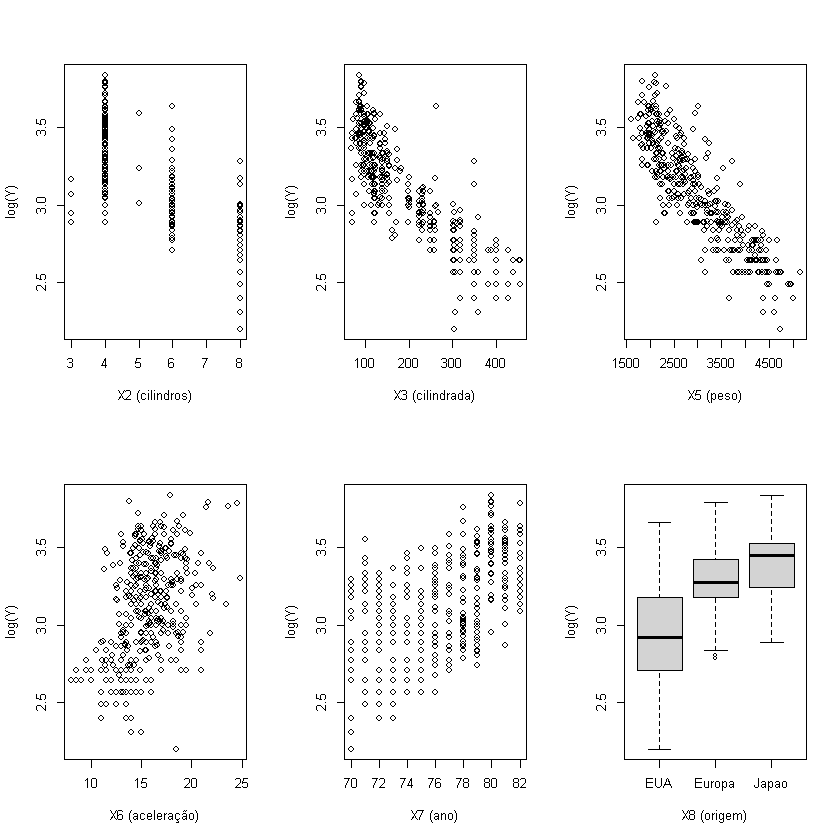

In [2]:
par(mfrow=c(2,3))
plot(auto$X2, log(auto$Y), xlab="X2 (cilindros)",  ylab="log(Y)")
plot(auto$X3, log(auto$Y), xlab="X3 (cilindrada)", ylab="log(Y)")
plot(auto$X5, log(auto$Y), xlab="X5 (peso)",       ylab="log(Y)")
plot(auto$X6, log(auto$Y), xlab="X6 (aceleração)", ylab="log(Y)")
plot(auto$X7, log(auto$Y), xlab="X7 (ano)",        ylab="log(Y)")
boxplot(log(Y) ~ X8, data=auto, xlab="X8 (origem)", ylab="log(Y)")
par(mfrow=c(1,1))

In [3]:
# correlação de log(Y) com cada preditora quantitativa
round(cor(cbind(logY=log(auto$Y), auto[,2:6]))[1,], 2)

# correlação entre as preditoras (multicolinearidade)
round(cor(auto[,2:6]), 2)

logY    X2    X3    X5    X6    X7 
 1.00 -0.83 -0.85 -0.88  0.45  0.58

,X2,X3,X5,X6,X7
X2,1.00,0.95,0.90,-0.51,-0.35
X3,0.95,1.00,0.93,-0.54,-0.37
X5,0.90,0.93,1.00,-0.42,-0.31
X6,-0.51,-0.54,-0.42,1.00,0.29
X7,-0.35,-0.37,-0.31,0.29,1.00


**A análise descritiva nos sugere que:**  

- **Cilindros, cilindrada e peso** ($X_2$, $X_3$ e $X_5$) têm relação **negativa e forte** com $\log(Y)$ (correlações −0,83, −0,85 e −0,88). Pode ser que carros maiores consomem mais. Na cilindrada($X3$) e no peso($X5$) a nuvem tem uma *leve* curvatura, indicando que a relação **talvez** seja linear em $\log$ dessas covariáveis, e não formas originais. Mas não vamos aplicar transformações nas covariáveis por enquanto.  
- **Aceleração** ($X_6$): tem correlação positiva com log(Y), mas fraca (0,45). Carros que demoram mais para chegar a 60 mph são os menos potentes, assim mais econômicos.  
- **Ano** ($X_7$): relação positiva (0,58). Carros mais novos parecem mais econômicos 
- **Origem** ($X_8$): carros europeus e japoneses têm $\log(Y)$ maior que os americanos, ou seja parecem que são mais eficientes.  

Note que (multicolinearidade): $X_2$, $X_3$ e $X_5$ são muito correlacionadas entre si (0,90 a 0,95). Elas estão medindo quase a mesma coisa ("tamanho do carro") e provavelmente não vamos precisar de todas elas no modelo.

## (b) Seleção de variáveis

**Método que vamos usar:** seleção backward com a função `step`:

1. começa com o modelo com todas as preditoras;
2. em cada passo, calcula o critério retirando cada variável, uma de cada vez;
3. retira a variável cuja saída mais diminui o critério;
4. para quando nenhuma retirada diminui o critério.

Usamos dois critérios: o **AIC** $= -2\ell + 2p$ e o **BIC** $= -2\ell + p\log(n)$. Com n = 398 nesse caso, o BIC penaliza mais o número de parâmetros e por isso tende a escolher modelos menores.

In [4]:
# modelo completo
aj1_auto <- glm(Y ~ X2 + X3 + X5 + X6 + X7 + X8, family=Gamma(link="log"), data=auto)
summary(aj1_auto)


Call:
glm(formula = Y ~ X2 + X3 + X5 + X6 + X7 + X8, family = Gamma(link = "log"), 
    data = auto)

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)  1.464e+00  1.476e-01   9.921  < 2e-16 ***
X2          -2.099e-02  1.128e-02  -1.862 0.063401 .  
X3           5.891e-04  2.598e-04   2.267 0.023914 *  
X5          -3.044e-04  2.073e-05 -14.685  < 2e-16 ***
X6           5.556e-03  2.729e-03   2.036 0.042426 *  
X7           3.201e-02  1.777e-03  18.013  < 2e-16 ***
X8Europa     8.562e-02  1.960e-02   4.369  1.6e-05 ***
X8Japao      7.107e-02  1.900e-02   3.741 0.000211 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for Gamma family taken to be 0.0138571)

    Null deviance: 44.7640  on 397  degrees of freedom
Residual deviance:  5.4742  on 390  degrees of freedom
AIC: 1911.1

Number of Fisher Scoring iterations: 4


In [5]:
# backward por AIC
aj2_auto <- step(aj1_auto, direction="backward")
summary(aj2_auto) #mantive todas as covariaveis...

Start:  AIC=1911.1
Y ~ X2 + X3 + X5 + X6 + X7 + X8

       Df Deviance    AIC
<none>      5.4742 1911.1
- X2    1   5.5222 1912.6
- X6    1   5.5324 1913.3
- X3    1   5.5450 1914.2
- X8    2   5.7951 1930.3
- X5    1   8.3993 2120.2
- X7    1  10.0046 2236.0



Call:
glm(formula = Y ~ X2 + X3 + X5 + X6 + X7 + X8, family = Gamma(link = "log"), 
    data = auto)

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)  1.464e+00  1.476e-01   9.921  < 2e-16 ***
X2          -2.099e-02  1.128e-02  -1.862 0.063401 .  
X3           5.891e-04  2.598e-04   2.267 0.023914 *  
X5          -3.044e-04  2.073e-05 -14.685  < 2e-16 ***
X6           5.556e-03  2.729e-03   2.036 0.042426 *  
X7           3.201e-02  1.777e-03  18.013  < 2e-16 ***
X8Europa     8.562e-02  1.960e-02   4.369  1.6e-05 ***
X8Japao      7.107e-02  1.900e-02   3.741 0.000211 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for Gamma family taken to be 0.0138571)

    Null deviance: 44.7640  on 397  degrees of freedom
Residual deviance:  5.4742  on 390  degrees of freedom
AIC: 1911.1

Number of Fisher Scoring iterations: 4


In [6]:
# backward por BIC
aj3_auto <- step(aj1_auto, direction="backward", k=log(nrow(auto)))
summary(aj3_auto) #tirou X2 (cilindros), X3 (cilindrada) e X6 (aceleração); sobrou só X5 X7 e X8


Start:  AIC=1942.99
Y ~ X2 + X3 + X5 + X6 + X7 + X8

       Df Deviance    AIC
- X2    1   5.5222 1940.5
- X6    1   5.5324 1941.2
- X3    1   5.5450 1942.1
<none>      5.4742 1943.0
- X8    2   5.7951 1954.2
- X5    1   8.3993 2148.1
- X7    1  10.0046 2263.9

Step:  AIC=1940.49
Y ~ X3 + X5 + X6 + X7 + X8

       Df Deviance    AIC
- X3    1   5.5489 1936.4
- X6    1   5.5755 1938.3
<none>      5.5222 1940.5
- X8    2   5.8321 1950.8
- X5    1   8.5199 2149.7
- X7    1  10.0572 2260.0

Step:  AIC=1936.43
Y ~ X5 + X6 + X7 + X8

       Df Deviance    AIC
- X6    1   5.5799 1932.7
<none>      5.5489 1936.4
- X8    2   5.8346 1944.8
- X7    1  10.1588 2259.1
- X5    1  17.8899 2810.4

Step:  AIC=1932.66
Y ~ X5 + X7 + X8

       Df Deviance    AIC
<none>      5.5799 1932.7
- X8    2   5.8792 1942.0
- X7    1  10.6001 2283.5
- X5    1  19.5521 2919.8



Call:
glm(formula = Y ~ X5 + X7 + X8, family = Gamma(link = "log"), 
    data = auto)

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)  1.494e+00  1.407e-01  10.618  < 2e-16 ***
X5          -2.851e-04  9.156e-06 -31.140  < 2e-16 ***
X7           3.204e-02  1.706e-03  18.788  < 2e-16 ***
X8Europa     7.795e-02  1.816e-02   4.292 2.24e-05 ***
X8Japao      6.047e-02  1.832e-02   3.300  0.00105 ** 
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for Gamma family taken to be 0.0140692)

    Null deviance: 44.7640  on 397  degrees of freedom
Residual deviance:  5.5799  on 393  degrees of freedom
AIC: 1912.7

Number of Fisher Scoring iterations: 4


**Resultado da seleção:**

- **AIC:** não retira nenhuma variável. Fica o modelo completo, mas com $X_2$ não significativa (p ≈ 0,06) e $X_3$ e $X_6$ só marginalmente significativas (p ≈ 0,02 e 0,04).
- **BIC:** retira $X_2$, $X_3$ e $X_6$. Fica $Y \sim X_5 + X_7 + X_8$.
- O teste conjunto de retirada de $X_2$, $X_3$ e $X_6$ não rejeita $H_0$ a 5% (teste F, p ≈ 0,056).

vamos usar o **modelo do BIC** (`aj3_auto`) como final. Além disso note que:
- no modelo completo, a cilindrada ($X_3$) aparece com coeficiente **positivo**, como se aumentar a cilindrada diminuísse o consumo, o que não faz sentido e contradiz o gráfico do item (a) e é efeito da multicolinearidade com $X_2$ e $X_5$;
- o modelo do BIC é bem mais simples, a diferença de AIC entre os dois é pequena (1911 contra 1913), todos os sinais fazem sentido e todas as variáveis são altamente significativas.

## (c) Modelo final e interpretação

In [7]:
summary(aj3_auto)


Call:
glm(formula = Y ~ X5 + X7 + X8, family = Gamma(link = "log"), 
    data = auto)

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)  1.494e+00  1.407e-01  10.618  < 2e-16 ***
X5          -2.851e-04  9.156e-06 -31.140  < 2e-16 ***
X7           3.204e-02  1.706e-03  18.788  < 2e-16 ***
X8Europa     7.795e-02  1.816e-02   4.292 2.24e-05 ***
X8Japao      6.047e-02  1.832e-02   3.300  0.00105 ** 
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for Gamma family taken to be 0.0140692)

    Null deviance: 44.7640  on 397  degrees of freedom
Residual deviance:  5.5799  on 393  degrees of freedom
AIC: 1912.7

Number of Fisher Scoring iterations: 4


In [8]:
# efeito do peso em escalas mais fáceis de ler
exp(100*coefficients(aj3_auto)["X5"])    # +100 libras

X5 
0.9718901

In [9]:
# phi na parametrização do livro e coeficiente de variação
dispersao <- summary(aj3_auto)$dispersion
1/dispersao        # phi
sqrt(dispersao)    # coeficiente de variação de Y

[1] 71.07726

[1] 0.1186136

In [10]:
# como a ligação é log, vamos ter os efeitos multiplicativos e ics de 95% exponenciando
exp(coefficients(aj3_auto))
exp(confint.default(aj3_auto))

(Intercept)          X5          X7    X8Europa     X8Japao 
  4.4546601   0.9997149   1.0325631   1.0810632   1.0623316

,2.5 %,97.5 %
(Intercept),3.381053,5.8691770
X5,0.999697,0.9997329
X7,1.029117,1.0360206
X8Europa,1.043258,1.1202382
X8Japao,1.024860,1.1011729


**Modelo ajustado com os coeficientes estimados fica:**

$$\log(\hat\mu) = 1{,}494 - 0{,}000285\,X_5 + 0{,}0320\,X_7 + 0{,}0779\,\text{Europa} + 0{,}0605\,\text{Japão}$$

Todas as estimativas são significativas ao nível de 5%. 

## Interpretação:
Com ligação log, $e^{\beta}$ é o **efeito multiplicativo** no consumo médio (mpg), mantidas as demais variáveis fixas:

- **Peso ($X_5$):** $e^{100 \times (-0{,}000285)} \approx 0{,}972$. Estima-se que para cada 100 libras a mais, a redução de o mpg médio seja cerca de **2,8%**, mantidas outras covariáveis constantes.
- **Ano ($X_7$):** $e^{0{,}0320} \approx 1{,}033$. A cada ano mais novo, estima-se que o mpg médio aumente cerca de **3,3%**. De 1970 a 1982 isso acumula $e^{12 \times 0{,}0320} \approx 1{,}47$, ou seja, **+47%**,], mantidas outras covariáveis constantes.
- **Origem ($X_8$):** com mesmo peso e ano, carros **europeus** fazem em média **8,1%** mais milhas por galão que os americanos ($e^{0{,}0779} \approx 1{,}081$), e os **japoneses**, **6,2%** a mais ($e^{0{,}0605} \approx 1{,}062$), mantidas outras covariáveis constantes.
- **Intercepto:** $e^{1{,}494} \approx 4{,}5$ seria o mpg médio de um carro americano de peso zero no "ano 0". Não tem interpretação prática nesse caso.
- **Dispersão:** $\hat\phi \approx 71$, que corresponde a um coeficiente de variação de cerca de **12%**: a variabilidade do mpg em torno da média é pequena.

## (d) Análise de diagnóstico

Alavanca, resíduo deviance, Cook, envelope e o resíduo quantílico. Como eu tô fazendo no notebook (ipynb) o `identify` não funciona, então o código escreve o número das observações que mais se destacam...

### Alavanca

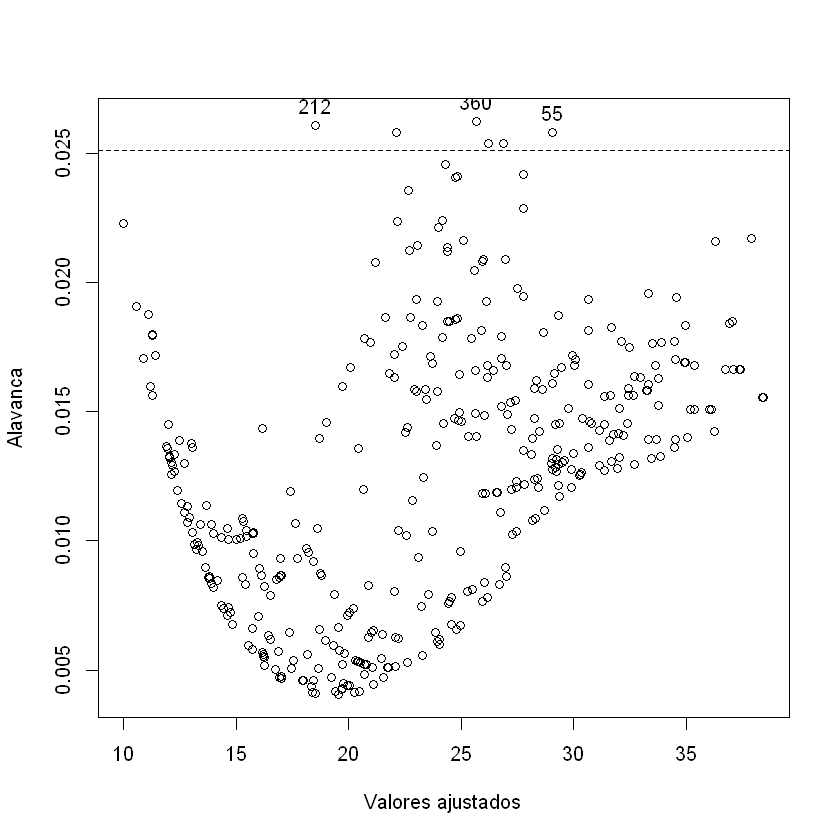

In [11]:
X <- model.matrix(aj3_auto)
w <- aj3_auto$weights
W <- diag(w)

# Pontos alavanca. Referência: 2p/n
auxh <- solve(t(X)%*%W%*%X)
H <- sqrt(W)%*%X%*%auxh%*%t(X)%*%sqrt(W)
h <- diag(H)
plot(fitted(aj3_auto), h, xlab="Valores ajustados", ylab="Alavanca")
abline(h=2*ncol(X)/nrow(X), lty=2)
dest_h <- order(h, decreasing=TRUE)[1:3]
text(fitted(aj3_auto)[dest_h], h[dest_h], labels=dest_h, pos=3)

Tem alguns que superam o limite de referência 2p/n, mas vendo o gráfico, não parece ter pontos de alavanca.

### Ponto discrepante por residuo deviance

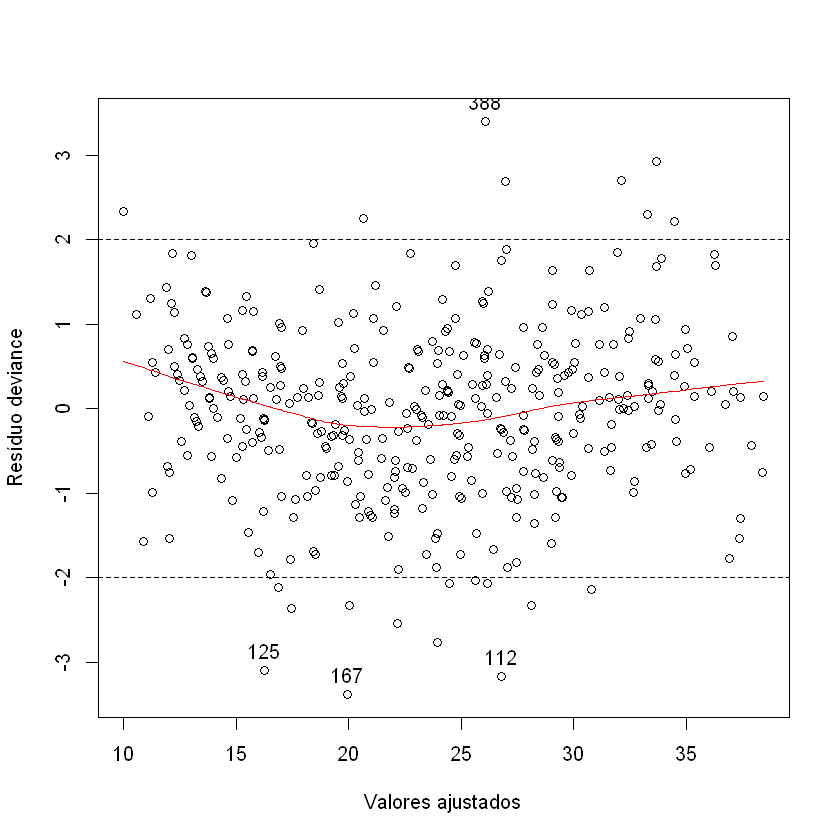

In [16]:
aux_tdi <- resid(aj3_auto, type='deviance')
aux_fi <- summary(aj3_auto)
fi <- 1/aux_fi$dispersion
tdi <- aux_tdi*sqrt(fi/(1-h))

plot(fitted(aj3_auto), tdi, xlab="Valores ajustados", ylab="Resíduo deviance")
abline(h=c(-2,2), lty=2)
lines(lowess(fitted(aj3_auto), tdi), col="red")     # tendência dos resíduos
dest_r <- order(abs(tdi), decreasing=TRUE)[1:4]
text(fitted(aj3_auto)[dest_r], tdi[dest_r], labels=dest_r, pos=3)



Parece ter alguns pontos discrepantes

### Ponto influente

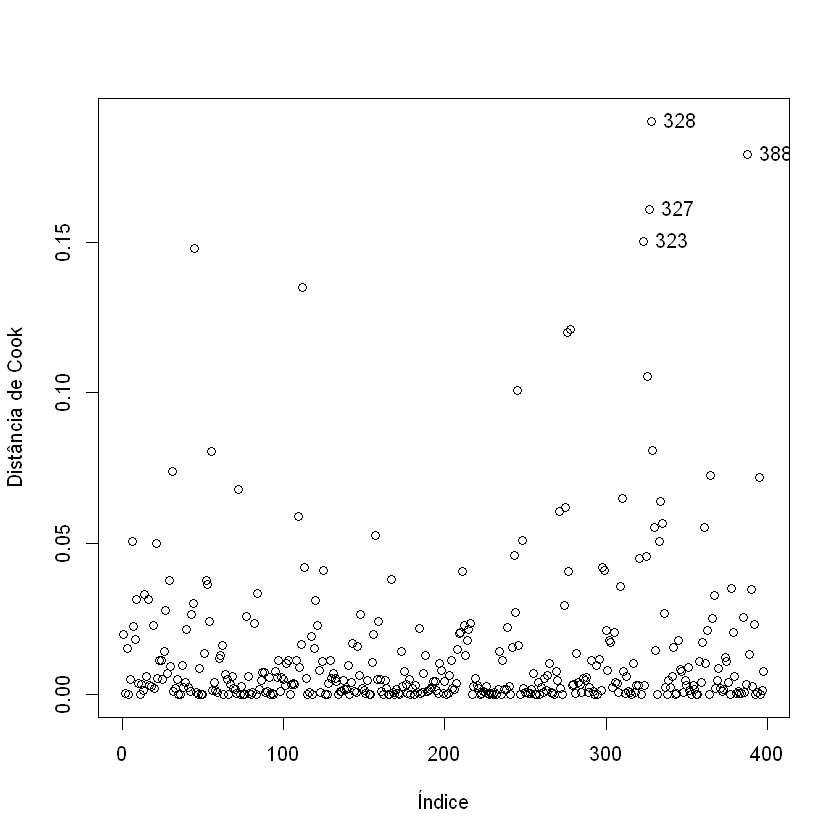

In [14]:
# Distância de Cook
ldi <- h*(tsi^2)/(1 - h)
plot(ldi, xlab="Índice", ylab="Distância de Cook")
dest_c <- order(ldi, decreasing=TRUE)[1:4]
text(dest_c, ldi[dest_c], labels=dest_c, pos=4)

Tem alguns pontos que se destacaram... as observações 328,388,327

### Envelope

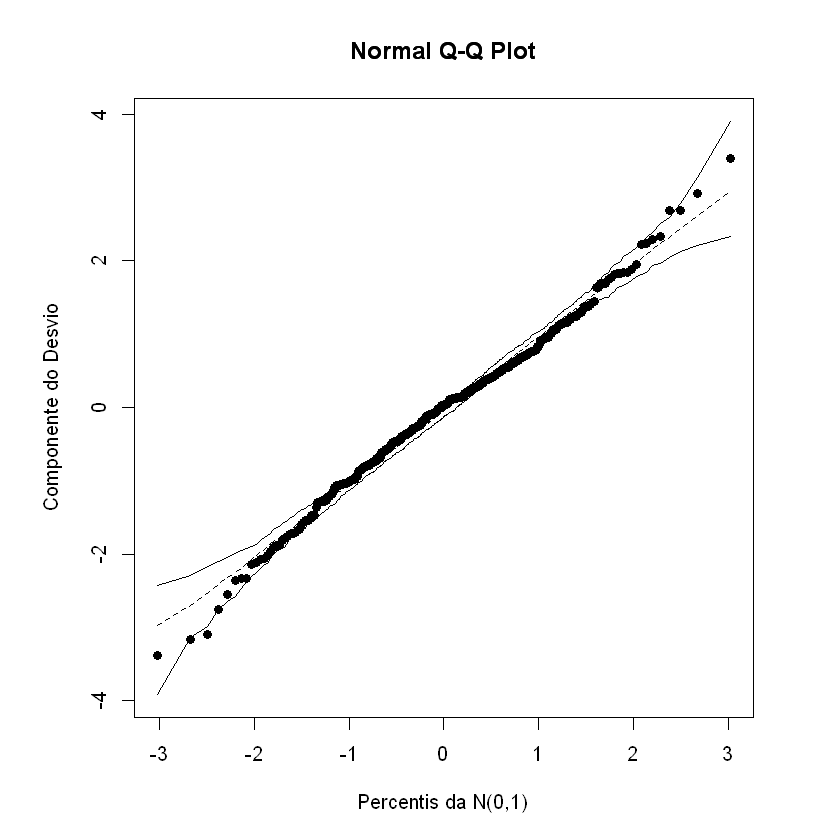

In [17]:
# Envelope (função do professor, na pasta MLG/Envelopes)
fit.model <- aj3_auto
source(paste0(envelopes, "envelope_gama.R"))

Maioria dos pontos estão dentro da banda/envelope.

Com os gráficso de cima, podemos dizer que o modelo gama com ligação log é **razoável de forma geral**

## (e) Pontos alavanca, discrepantes e influentes

Pelos gráficos do item (d), os destaques são:

- não há alavancagem alta de fato
- tem alguns pontos influentes
- as observações 328,388,327 parecem ser influentes (distancia de cook maior)

Três dos quatro pontos mais influentes são **carros a diesel**: o tipo de combustível não está no banco de dados, e o motor diesel é mais econômico.

Vamos reajustar o modelo sem os três pontos mais influentes (maior distância de Cook):

In [19]:
# Os 3 pontos com maior distância de Cook
pontos <- order(ldi, decreasing=TRUE)[1:3]
auto[pontos, ]

aj3_auto_sem <- glm(Y ~ X5 + X7 + X8, family=Gamma(link="log"), data=auto, subset=-pontos)
summary(aj3_auto_sem)

# Variação percentual das estimativas
round((coefficients(aj3_auto_sem) - coefficients(aj3_auto))/coefficients(aj3_auto)*100, 1)

,Y,X2,X3,X5,X6,X7,X8
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
328,36.4,5,121,2950,19.9,80,Europa
388,38.0,6,262,3015,17.0,82,EUA
327,43.4,4,90,2335,23.7,80,Europa



Call:
glm(formula = Y ~ X5 + X7 + X8, family = Gamma(link = "log"), 
    data = auto, subset = -pontos)

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)  1.591e+00  1.366e-01  11.643  < 2e-16 ***
X5          -2.869e-04  8.841e-06 -32.456  < 2e-16 ***
X7           3.082e-02  1.657e-03  18.596  < 2e-16 ***
X8Europa     6.794e-02  1.772e-02   3.833 0.000147 ***
X8Japao      6.257e-02  1.768e-02   3.539 0.000450 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for Gamma family taken to be 0.01307098)

    Null deviance: 43.7939  on 394  degrees of freedom
Residual deviance:  5.2037  on 390  degrees of freedom
AIC: 1870.4

Number of Fisher Scoring iterations: 4


(Intercept)          X5          X7    X8Europa     X8Japao 
        6.5         0.6        -3.8       -12.8         3.5

In [ ]:
# retirando um ponto de cada vez
for (k in pontos) {
  ajk <- glm(Y ~ X5 + X7 + X8, family=Gamma(link="log"), data=auto, subset=-k)
  cat("\nSem a observação", k, "- variação % das estimativas e p-valores:\n")
  print(round(cbind(var_pct = (coefficients(ajk) - coefficients(aj3_auto))/coefficients(aj3_auto)*100,
                    p_valor = summary(ajk)$coefficients[,4]), 4))
}

**Conclusão:** o único coeficiente que muda de forma notável é o da **origem Europa**, que cai cerca de 13% sem os três pontos (dois deles são carros europeus a diesel), mas continua significativo (p ≈ 0,0001). Peso e ano mudam menos de 4%. **Nenhuma variável muda de sinal nem perde significância**, então nenhum ponto altera as conclusões. Com 398 observações, cada carro isolado tem pouco peso. Mantemos todas as observações.

## (f) Pseudo $R^2$

Nesse caso o Pseudo $R^2$ pode ser definida como a proporção do desvio explicada: $R^2_D = 1 - D(\mathbf{y}; \hat{\boldsymbol\mu})/D_0$, onde $D_0$ é o desvio do modelo só com intercepto.

In [ ]:
R2_desvio <- 1 - aj3_auto$deviance/aj3_auto$null.deviance
R2_desvio

**Comentário:** $R^2_{\text{pseudo}} \approx 0{,}88$. O modelo explica cerca de 88% da variabilidade de $\log(Y)$ com só três variáveis (peso, ano e origem), um ajuste muito bom. Diferente do $R^2$ da regressão linear, o pseudo $R^2$ não tem interpretação exata de "proporção de variância explicada" de $Y$ e serve mais para comparar modelos.